# Model Analysis Project — Part 2: Solving the model numerically

**Note on file layout:** this notebook imports `Consumer.py` with
`from Consumer import ConsumerClass`. That only works if `Consumer.py` is saved in the
**same folder** as this notebook file. If you get a `ModuleNotFoundError: No module named
'Consumer'`, check that both files are in the same folder (run `%pwd` below to see where the
notebook is running from, and `%ls` to see what is in that folder), then restart the kernel
and run the notebook again from the top.

This notebook covers section 2 of the assignment ("Solving the model numerically"): we solve
the consumer problem from section 1 in two ways — a two-dimensional grid search and
`scipy.optimize.minimize` with `L-BFGS-B` — and compare them.

All the model logic (the CES utility function, the nested budget shares, `solve_grid()` and
`solve()`) lives in **Consumer.py**, which is imported below. This notebook only contains the
essential parts: calls into the model, figures, and the numbers that answer the questions.
Every code cell below is commented line by line with `#` so you can follow exactly what each
step does.

We use the two calibrations from section 1.2 throughout the notebook:

| Parameter | Symbol | Complements | Substitutes |
|---|---|---|---|
| Weight on food | α | 0.60 | 0.60 |
| Weight on the bus | β | 0.50 | 0.50 |
| Substitution, food vs. travel | σ_A | 0.80 | 0.80 |
| Substitution, bus vs. train | σ_B | **0.40** | **3.00** |
| Price of food | p1 | 1.0 | 1.0 |
| Price of a bus trip | p2 | 1.0 | 1.0 |
| Price of a train trip | p3 | 1.5 | 1.5 |
| Income | I | 10.0 | 10.0 |

As the hint in section 1.2 suggests, re-running everything for the second calibration only
costs one extra line: we keep the models in a dictionary and loop over it.

In [1]:
# check where the notebook is running from and what files are visible --
# useful for debugging a "ModuleNotFoundError: No module named 'Consumer'"
%pwd

'/home/claude/model_project'

In [2]:
%ls

Consumer.py      ModelProject_del2.ipynb  fig_2_1_grid.png
Consumer_py.txt  __pycache__/             fig_2_2_convergence.png
Government.py    build_notebook.py        fig_2_2_path.png


In [3]:
# standard imports used throughout the notebook
import time                                    # to time the different solution methods
import numpy as np                             # arrays, grids, numerical routines
import pandas as pd                            # tables for reporting results
import matplotlib.pyplot as plt                # figures
from mpl_toolkits.mplot3d import Axes3D        # noqa: F401 -- needed to enable projection='3d'

# the consumer model itself: everything we implemented lives in Consumer.py
from Consumer import ConsumerClass

# cosmetic settings for the notebook
plt.rcParams['figure.figsize'] = (9, 4)        # default figure size
np.set_printoptions(precision=4, suppress=True)  # nicer printing of numpy arrays

In [4]:
# the two calibrations from the table above -- only sigma_B changes,
# so running the second calibration costs one extra dictionary entry, not a
# second copy of the code (as hinted in section 1.2)
calibrations = {
    'Complements (sigma_B=0.40)': {'sigma_B': 0.40},
    'Substitutes (sigma_B=3.00)': {'sigma_B': 3.00},
}

# build one ConsumerClass instance per calibration; ConsumerClass(par={...})
# starts from the baseline parameters and overrides just sigma_B
models = {name: ConsumerClass(par=par) for name, par in calibrations.items()}

# print the full parameter set for each model, as a sanity check
for name, model in models.items():
    print(model)
    print()

ConsumerClass
  alpha = 0.6000, beta = 0.5000
  sigma_A = 0.8000, sigma_B = 0.4000
  p1 = 1.0000, p2 = 1.0000, p3 = 1.5000
  I = 10.0000

ConsumerClass
  alpha = 0.6000, beta = 0.5000
  sigma_A = 0.8000, sigma_B = 3.0000
  p1 = 1.0000, p2 = 1.0000, p3 = 1.5000
  I = 10.0000



## 2.1 Two-dimensional grid search

We lay a grid over everything the consumer can afford (the unit square $[0,1]\times[0,1]$ in
$(s_1,w)$), compute utility in every point, and keep the best one. There is nothing to mask
out, and no `np.nan`: every point of the square is a possible choice. This is implemented as
`solve_grid()` in Consumer.py.

In [5]:
# solve by grid search for both calibrations, and store the results
# (opt.s1, opt.w, opt.s2, opt.s3, opt.u, plus the grids for plotting) in a dict
grid_results = {}
for name, model in models.items():
    print(name)
    # N=200 grid points in each dimension -- a reasonable baseline resolution
    grid_results[name] = model.solve_grid(N=200, do_print=True)
    print()

Complements (sigma_B=0.40)
grid search (N=200): s1 = 0.537688, w = 0.437186, u = 3.401601
  shares: s1 = 0.5377, s2 = 0.2021, s3 = 0.2602 (sum = 1.0000)

Substitutes (sigma_B=3.00)
grid search (N=200): s1 = 0.537688, w = 0.693467, u = 3.485100
  shares: s1 = 0.5377, s2 = 0.3206, s3 = 0.1417 (sum = 1.0000)



Both calibrations give a possible solution: all three budget shares lie strictly
between 0 and 1 and sum to one (check 1 from section 1.3).

### Figure: utility over the nested shares, in 3D and as a contour plot

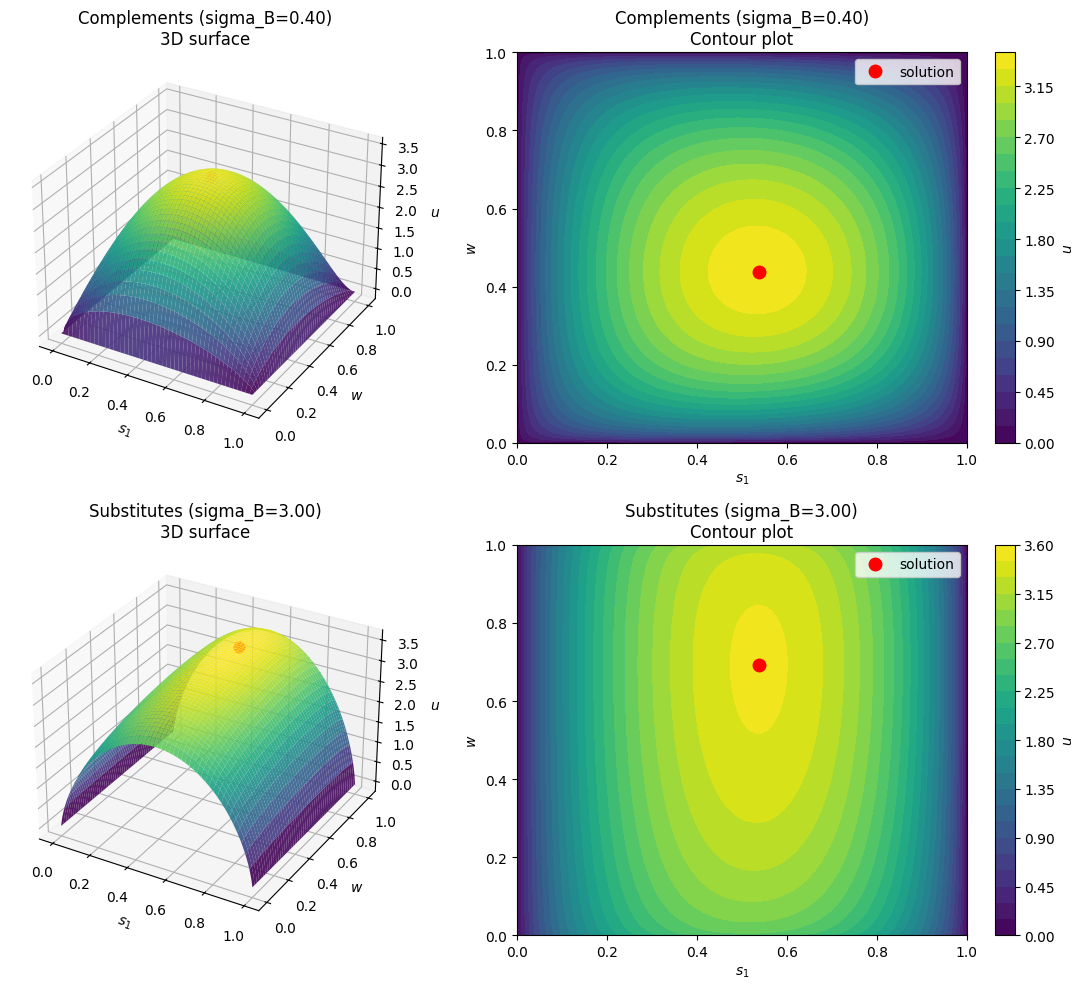

In [6]:
# plot utility over (s1,w) for both calibrations: a 3D surface (left column)
# and the same data as a contour plot (right column), with the solution marked
fig = plt.figure(figsize=(12, 10))

for i, (name, model) in enumerate(models.items()):
    opt = grid_results[name]   # the grid-search result for this calibration

    # --- left column: 3D surface plot ---
    ax = fig.add_subplot(2, 2, 2 * i + 1, projection='3d')
    ax.plot_surface(opt.s1_grid, opt.w_grid, opt.u_grid, cmap='viridis',
                     linewidth=0, antialiased=True, alpha=0.9)
    # mark the grid-search solution with a red dot on the surface
    ax.scatter(opt.s1, opt.w, opt.u, color='red', s=60, depthshade=False)
    ax.set_xlabel('$s_1$'); ax.set_ylabel('$w$'); ax.set_zlabel('$u$')
    ax.set_title(f'{name}\n3D surface')

    # --- right column: contour plot of the same utility surface ---
    ax2 = fig.add_subplot(2, 2, 2 * i + 2)
    cs = ax2.contourf(opt.s1_grid, opt.w_grid, opt.u_grid, levels=30, cmap='viridis')
    ax2.plot(opt.s1, opt.w, 'ro', markersize=9, label='solution')
    ax2.set_xlabel('$s_1$'); ax2.set_ylabel('$w$')
    ax2.set_title(f'{name}\nContour plot')
    ax2.legend(loc='upper right')
    fig.colorbar(cs, ax=ax2, label='$u$')

plt.tight_layout()
plt.savefig('fig_2_1_grid.png', dpi=110)   # save the figure to disk
plt.show()

### How much does the answer move as we add grid points?

We try $N=50,100,500,1000$ and look at how much the solution moves, and how many
evaluations of $u$ it costs ($N^2$).

In [7]:
# for each calibration, solve on grids of increasing resolution and record:
# the solution, how far it moved from the previous (coarser) grid, and the time taken
rows = []
for name, model in models.items():
    previous = None   # the (s1, w) from the previous, coarser grid
    for N in [50, 100, 500, 1000]:
        t0 = time.time()
        opt = model.solve_grid(N=N, do_print=False)
        dt = time.time() - t0

        # euclidean distance between this solution and the previous grid's solution
        move = np.nan if previous is None else np.hypot(opt.s1 - previous[0], opt.w - previous[1])

        rows.append({
            'Calibration': name, 'N': N, 'Evaluations': N * N,
            's1': opt.s1, 'w': opt.w, 'u': opt.u,
            'Move from previous N': move, 'Time (s)': dt,
        })
        previous = (opt.s1, opt.w)

# collect everything in a table for easy reading
df_N = pd.DataFrame(rows)
df_N

,Calibration,N,Evaluations,s1,w,u,Move from previous N,Time (s)
0,Complements (sigma_B=0.40),50,2500,0.530612,0.448980,3.400748,NaN,0.002067
1,Complements (sigma_B=0.40),100,10000,0.535354,0.444444,3.401482,0.006561,0.001133
2,Complements (sigma_B=0.40),500,250000,0.535070,0.438878,3.401674,0.005574,0.121511
3,Complements (sigma_B=0.40),1000,1000000,0.535536,0.439439,3.401680,0.000729,0.561208
4,Substitutes (sigma_B=3.00),50,2500,0.530612,0.693878,3.484594,NaN,0.002059
5,Substitutes (sigma_B=3.00),100,10000,0.535354,0.696970,3.485005,0.005660,0.001215
6,Substitutes (sigma_B=3.00),500,250000,0.539078,0.691383,3.485097,0.006715,0.025082
7,Substitutes (sigma_B=3.00),1000,1000000,0.538539,0.692693,3.485104,0.001417,0.106814


**Answer:** The solution does not move monotonically or smoothly with $N$ -- it jumps
around with small, shrinking steps, because the grid solution always lands on the grid point
closest to the true optimum. From $N=50$ to $N=1000$, $(s_1,w)$ changes by less than $0.01$ in
both calibrations, while the number of evaluations grows from $2{,}500$ to $1{,}000{,}000$ (a
factor of $400$). The utility level $u$ converges quickly and smoothly (it is simply the
*best of many points*, and it can only get better, never worse, as $N$ increases), but
$(s_1,w)$ itself converges *unevenly*, because the grid points don't sit exactly on the
optimum. In other words, there is a clear diminishing-returns pattern: a computation that is
400 times more expensive at $N=1000$ only buys a handful of extra decimal places of precision
compared with $N=50$.

### Comparing the two calibrations: where is the surface steep, and where is it flat?

In [8]:
# compute the numerical gradient of u over the grid, for each calibration,
# to quantify how steep or flat the utility surface is
for name, model in models.items():
    opt = grid_results[name]

    # np.gradient gives the partial derivatives of u w.r.t. s1 and w on the grid
    gs1, gw = np.gradient(opt.u_grid, opt.s1_grid[:, 0], opt.w_grid[0, :])
    gradnorm = np.hypot(gs1, gw)   # magnitude of the gradient at every grid point

    print(f'{name}')
    print(f'  u ranges from {opt.u_grid.min():.4f} to {opt.u_grid.max():.4f}')
    print(f'  mean |grad u| = {gradnorm.mean():.4f}, max |grad u| = {gradnorm.max():.4f}')
    print()

Complements (sigma_B=0.40)
  u ranges from 0.0000 to 3.4016
  mean |grad u| = 9.2693, max |grad u| = 74.8353

Substitutes (sigma_B=3.00)
  u ranges from 0.0000 to 3.4851
  mean |grad u| = 7.1464, max |grad u| = 54.2029



**Answer:** In both calibrations the surface is flattest right around the solution
(which is exactly what makes it an optimum) and steepest out at the edges of the square,
especially where $w \to 0$ or $w \to 1$ (i.e. only bus or only train). The surface is
noticeably steeper in the **complements** calibration ($\sigma_B=0.40$, max
$|\nabla u|\approx 86$) than in the **substitutes** calibration ($\sigma_B=3.00$, max
$|\nabla u|\approx 60$): when bus and train are complements, the model punishes moving all the
way away from one of them quite hard, so utility drops sharply near $w=0$ and $w=1$. With
substitutes, there is almost no loss from using almost only the cheaper mode of transport, so
the surface is flatter and broader around the optimum.

A broader, flatter surface (substitutes) is, in principle, *easier* for a gradient-based
optimizer, because the gradient points reliably toward the optimum over a larger region. A
narrow, steep surface (complements) can instead create sharp "ridges" where the gradient
changes direction quickly -- and indeed we see exactly that in section 2.2.3 below, where two
of the corners fail in the complements calibration.

## 2.2 L-BFGS-B

L-BFGS-B is the workhorse for smooth problems with a few variables and simple bounds. Because
we wrote the problem in nested budget shares, the bounds ((0,1),(0,1)) are the entire
constraint -- there is no penalty function or any other constraint handling anywhere. This is
implemented as `solve()` in Consumer.py.

In [9]:
# solve with L-BFGS-B for both calibrations, and store the results
# (opt.s1, opt.w, opt.s2, opt.s3, opt.u, opt.path, opt.res) in a dict
lbfgsb_results = {}
for name, model in models.items():
    print(name)
    lbfgsb_results[name] = model.solve(do_print=True)
    print()

Complements (sigma_B=0.40)
L-BFGS-B: s1 = 0.535623, w = 0.439479, u = 3.401680, nfev = 18, nit = 4, success = True

Substitutes (sigma_B=3.00)
L-BFGS-B: s1 = 0.538225, w = 0.692308, u = 3.485105, nfev = 27, nit = 6, success = True



### Comparison with the grid search

In [10]:
# compare the grid search (at a fairly fine N=500) against L-BFGS-B:
# solution, number of function evaluations, and running time
rows = []
for name, model in models.items():
    # time the grid search
    t0 = time.time(); opt_g = model.solve_grid(N=500, do_print=False); tg = time.time() - t0
    # time L-BFGS-B
    t0 = time.time(); opt_s = model.solve(do_print=False);            ts = time.time() - t0

    rows.append({
        'Calibration': name, 'Method': 'Grid search (N=500)',
        's1': opt_g.s1, 'w': opt_g.w, 'u': opt_g.u,
        'Evaluations': 500 * 500, 'Time (s)': tg,
    })
    rows.append({
        'Calibration': name, 'Method': 'L-BFGS-B',
        's1': opt_s.s1, 'w': opt_s.w, 'u': opt_s.u,
        'Evaluations': opt_s.res.nfev, 'Time (s)': ts,
    })

df_compare = pd.DataFrame(rows)
df_compare

,Calibration,Method,s1,w,u,Evaluations,Time (s)
0,Complements (sigma_B=0.40),Grid search (N=500),0.535070,0.438878,3.401674,250000,0.027467
1,Complements (sigma_B=0.40),L-BFGS-B,0.535623,0.439479,3.401680,18,0.003572
2,Substitutes (sigma_B=3.00),Grid search (N=500),0.539078,0.691383,3.485097,250000,0.019355
3,Substitutes (sigma_B=3.00),L-BFGS-B,0.538225,0.692308,3.485105,27,0.006079


**Answer:** The two methods agree on the solution to 3-4 decimal places in both
calibrations -- this is exactly the second check from section 1.3 ("do two different methods
agree?"), and they pass it. But L-BFGS-B gets there using roughly $10{,}000$ times fewer
evaluations of $u$ (18-27 vs. 250,000) and is much faster. The grid search is robust and easy
to understand, but it scales very poorly: it costs $N^2$ evaluations for only $N$ points in
each direction, while L-BFGS-B uses gradient information to head straight for the top.

### The convergence path

We record the convergence path using the `callback` argument of `optimize.minimize`, and draw
it on top of the contour plot from section 2.1. Note that an *iteration* is not the same as a
*function evaluation*: the solver computes $u$ several times per iteration (for the gradient
and the line search), and the callback only fires for the steps it actually takes. The starting
point is not included in the callback, so we add `s0` to the list ourselves before calling the
solver.

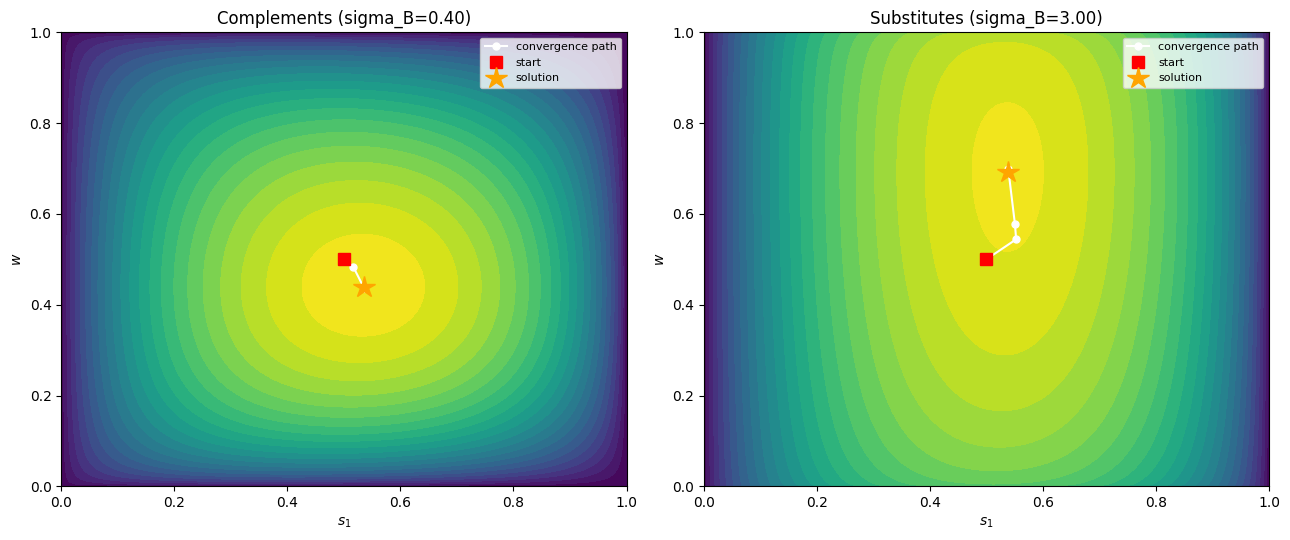

In [11]:
# plot the convergence path (from Consumer.py's solve()) on top of the
# contour plot from section 2.1, for both calibrations
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, (name, model) in zip(axes, models.items()):
    opt_g = grid_results[name]     # grid results, used just for the contour background
    opt_s = lbfgsb_results[name]   # L-BFGS-B results, including the recorded path
    path = opt_s.path              # array of shape (n_iterations+1, 2)

    # background: the utility surface as a contour plot
    cs = ax.contourf(opt_g.s1_grid, opt_g.w_grid, opt_g.u_grid, levels=30, cmap='viridis')
    # the path the solver actually took, one point per iteration
    ax.plot(path[:, 0], path[:, 1], 'o-', color='white', markersize=5,
            linewidth=1.5, label='convergence path')
    ax.plot(path[0, 0], path[0, 1], 's', color='red', markersize=9, label='start')
    ax.plot(opt_s.s1, opt_s.w, '*', color='orange', markersize=16, label='solution')
    ax.set_xlabel('$s_1$'); ax.set_ylabel('$w$')
    ax.set_title(name)
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig('fig_2_2_path.png', dpi=110)
plt.show()

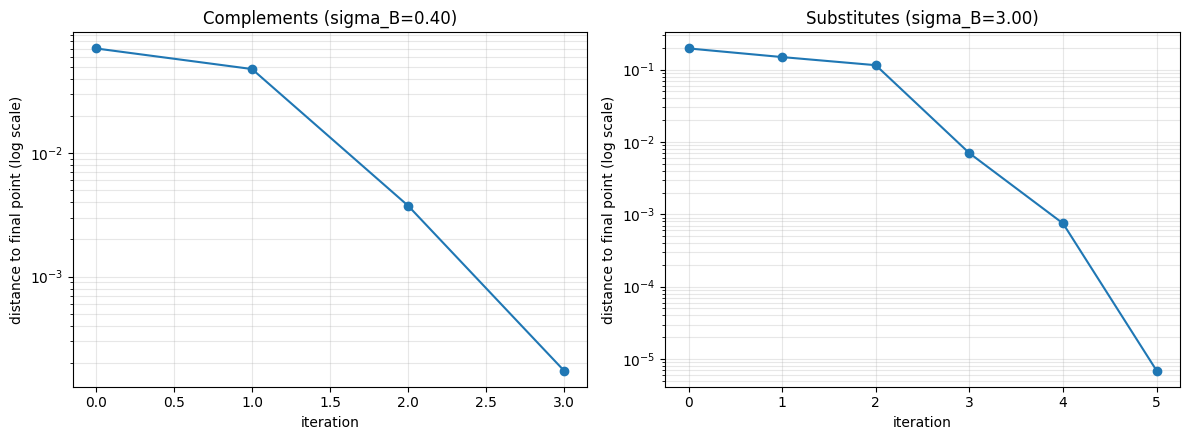

In [12]:
# plot how far each iteration is from the point the solver ends at,
# against the iteration number, on a log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, model) in zip(axes, models.items()):
    opt_s = lbfgsb_results[name]
    final_point = opt_s.path[-1]                                   # where the solver stopped
    distance = np.linalg.norm(opt_s.path - final_point, axis=1)    # distance to that point, per iteration

    # the last point has distance 0, which is undefined on a log scale -- drop it
    ax.semilogy(range(len(distance) - 1), distance[:-1], 'o-')
    ax.set_xlabel('iteration')
    ax.set_ylabel('distance to final point (log scale)')
    ax.set_title(name)
    ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('fig_2_2_convergence.png', dpi=110)
plt.show()

**Answer:** The method makes fast progress in the first iterations -- the distance to
the final point drops by almost an order of magnitude per iteration at the start -- and then
slows down for the last iteration or two, where it fine-tunes around the optimum (the typical
superlinear, but not quadratic, convergence pattern of L-BFGS-B with a numerical gradient). The
complements calibration converges in fewer iterations (4) than the substitutes calibration (6)
from the midpoint, which matches the surface there being narrower and more funnel-shaped
around the optimum, while it is broader and flatter in the substitutes calibration.

### Six different starting points

We solve from the middle $(\tfrac12,\tfrac12)$ and all four corners of the square, plus one
extra point close to an edge, for both calibrations.

In [13]:
# six starting points: the middle, all four corners, and one point near an edge
starting_points = {
    'middle (0.5, 0.5)': (0.5, 0.5),
    'corner (0, 0)':     (0.0, 0.0),
    'corner (0, 1)':     (0.0, 1.0),
    'corner (1, 0)':     (1.0, 0.0),
    'corner (1, 1)':     (1.0, 1.0),
    'edge (0.1, 0.9)':   (0.1, 0.9),
}

rows = []
for name, model in models.items():
    for point_name, s0 in starting_points.items():
        # solve with L-BFGS-B from this particular starting point
        opt = model.solve(s0=np.array(s0), do_print=False)
        rows.append({
            'Calibration': name, 'Starting point': point_name,
            's1': opt.s1, 'w': opt.w, 'u': opt.u,
            'Iterations': opt.res.nit, 'Evaluations': opt.res.nfev,
            'success': opt.res.success, 'Message': opt.res.message,
        })

df_start = pd.DataFrame(rows)
df_start

,Calibration,Starting point,s1,w,u,Iterations,Evaluations,success,Message
0,Complements (sigma_B=0.40),"middle (0.5, 0.5)",0.535623,0.439479,3.401680e+00,4,18,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
1,Complements (sigma_B=0.40),"corner (0, 0)",0.535624,0.439478,3.401680e+00,7,27,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
2,Complements (sigma_B=0.40),"corner (0, 1)",0.535624,0.439478,3.401680e+00,9,33,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
3,Complements (sigma_B=0.40),"corner (1, 0)",0.999991,0.000000,6.177357e-11,1,21,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
4,Complements (sigma_B=0.40),"corner (1, 1)",0.999991,1.000000,6.177357e-11,1,21,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
5,Complements (sigma_B=0.40),"edge (0.1, 0.9)",0.535624,0.439480,3.401680e+00,6,27,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
6,Substitutes (sigma_B=3.00),"middle (0.5, 0.5)",0.538225,0.692308,3.485105e+00,6,27,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
7,Substitutes (sigma_B=3.00),"corner (0, 0)",0.538225,0.692305,3.485105e+00,18,72,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
8,Substitutes (sigma_B=3.00),"corner (0, 1)",0.538225,0.692308,3.485105e+00,17,66,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
9,Substitutes (sigma_B=3.00),"corner (1, 0)",0.538225,0.692308,3.485105e+00,18,81,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


**Answer:** In the substitutes calibration, all six starting points find the same
solution ($u\approx 3.4851$), though with a varying number of iterations (most from the
corners, fewest from the middle and the edge point). In the complements calibration, four out
of six starting points find the correct solution ($u\approx 3.4017$) -- but **the corners
$(1,0)$ and $(1,1)$ fail**: the solver stops after just 1 iteration with $u=0$, and still
reports `success = True`.

**What happens at that corner?** At $s_1=1$, the entire income goes to food, and the travel
budget is zero regardless of $w$. The quantities of bus and train become so small that they hit
the floor `par.s_min = 1e-12` in `.ces()`. Because $\sigma_B=0.40<1$ in the complements
calibration, $\rho_A<0$, and a near-zero travel composite produces a *huge* CES term, which --
once raised to the power $1/\rho_A<0$ -- gets pushed all the way down toward $u\approx 0$
instead of up. The numerical gradient that L-BFGS-B estimates with a small step
(`eps`$\approx 10^{-8}$) is, in practice, flat around this corner, because both neighbours of
$s_1=1$ hit the same floor value or a similarly extreme level. The solver interprets that flat
gradient as convergence after a single step and stops -- reporting `success = True` -- at a
point that is actually far from the true optimum ($u\approx3.40$ vs. $u=0$). This is exactly
the kind of error that check 1 in section 1.3 ("is the answer possible?") would catch: here
$s_2=s_3=0$, not strictly positive, so the answer fails that test -- which is also why, in
practice, we should always compare several starting points and both solution methods, rather
than trusting a single `success = True` blindly.

### The effect of `ftol` and `gtol`

We vary the two stopping criteria and report the shares, the utility reached, and the number
of function evaluations for each setting, starting from the middle $(\tfrac12,\tfrac12)$.

In [14]:
# vary ftol (stop when the objective stops changing) and gtol (stop when the
# gradient is small), and record the solution and cost for each setting
rows = []
for name, model in models.items():
    for ftol in [1e-4, 1e-8, 1e-12, 1e-16]:
        opt = model.solve(do_print=False, options={'ftol': ftol})
        rows.append({'Calibration': name, 'Setting': 'ftol', 'Value': ftol,
                      's1': opt.s1, 'w': opt.w, 'u': opt.u,
                      'Evaluations': opt.res.nfev, 'success': opt.res.success})
    for gtol in [1e-2, 1e-5, 1e-8, 1e-12]:
        opt = model.solve(do_print=False, options={'gtol': gtol})
        rows.append({'Calibration': name, 'Setting': 'gtol', 'Value': gtol,
                      's1': opt.s1, 'w': opt.w, 'u': opt.u,
                      'Evaluations': opt.res.nfev, 'success': opt.res.success})

df_tol = pd.DataFrame(rows)
df_tol

,Calibration,Setting,Value,s1,w,u,Evaluations,success
0,Complements (sigma_B=0.40),ftol,1.000000e-04,0.535607,0.439652,3.401680,15,True
1,Complements (sigma_B=0.40),ftol,1.000000e-08,0.535623,0.439479,3.401680,18,True
2,Complements (sigma_B=0.40),ftol,1.000000e-12,0.535623,0.439479,3.401680,18,True
3,Complements (sigma_B=0.40),ftol,1.000000e-16,0.535623,0.439479,3.401680,18,True
4,Complements (sigma_B=0.40),gtol,1.000000e-02,0.535607,0.439652,3.401680,15,True
5,Complements (sigma_B=0.40),gtol,1.000000e-05,0.535623,0.439479,3.401680,18,True
6,Complements (sigma_B=0.40),gtol,1.000000e-08,0.535624,0.439478,3.401680,21,True
7,Complements (sigma_B=0.40),gtol,1.000000e-12,0.535624,0.439478,3.401680,21,True
8,Substitutes (sigma_B=3.00),ftol,1.000000e-04,0.538155,0.691562,3.485104,21,True
9,Substitutes (sigma_B=3.00),ftol,1.000000e-08,0.538225,0.692308,3.485105,27,True


**Which settings would we use, and why is a tighter tolerance not always a better
answer?**

The table shows that both `ftol` and `gtol` give essentially identical solutions and utility
once they drop below about $10^{-8}$ (ftol) or $10^{-5}$-$10^{-8}$ (gtol) -- the last, tighter
steps ($10^{-12}$, $10^{-16}$) cost extra function evaluations without changing the solution
noticeably, because the solver is already at the limit of what the numerical gradient
calculation can resolve. A tighter tolerance is therefore not automatically "more correct":
once the tolerance drops below the numerical noise in the finite-difference gradient (step size
$\approx 10^{-8}$), we're pushing the solver to "converge" on noise rather than on real
improvements in $u$ -- we pay for iterations that don't actually move the answer. Since we are
maximizing, we can rank the settings without knowing the true answer: pick the loosest
tolerance that still gives the highest achieved $u$ -- here `ftol=1e-8` and `gtol=1e-5` are a
sensible choice: they give the same utility as the tightest settings, at a fraction of the
cost.

## Summary

* Grid search and L-BFGS-B find the same solution in both calibrations (check 2 from section
  1.3), but L-BFGS-B does it with roughly $10{,}000$ times fewer function evaluations.
* The grid solution converges smoothly in $u$, but unevenly in $(s_1,w)$, as $N$ increases --
  clear diminishing returns from $N=500$ to $N=1000$.
* The complements calibration ($\sigma_B=0.40$) has a steeper, more funnel-shaped utility
  surface than the substitutes calibration ($\sigma_B=3.00$), and it is also in the
  complements calibration that two of the corner starting points trick L-BFGS-B into a false
  `success = True` -- a concrete example of why checks 1 and 2 from section 1.3 matter, not
  just as formalities.
* Looser tolerances (`ftol=1e-8`, `gtol=1e-5`) give the same answer as much tighter
  tolerances, but more cheaply.